

1. **Partie A** — Classifier les anomalies par *cause technique* (optique ou administrative)
2. **Partie B** — *Localiser* les anomalies (carte OLT, port, combinaison carte+port)
3. **Partie C (K-Means)** — *Regrouper* / *Clustériser* les anomalies en 4 groupes : `carte`, `port`, `admin`, `autre`


In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'

import pandas as pd
import numpy  as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster       import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics       import silhouette_score
from sklearn.decomposition import PCA
from scipy.spatial.distance import cdist
import joblib

sns.set(style='whitegrid')
%matplotlib inline

# Charger le dataset complet pour avoir les colonnes Carte, Port, et Etats
df = pd.read_excel('dataset_ml.xlsx')

# Synchroniser avec les 721 anomalies du pipeline Z-Score + Règles
y_final_z = joblib.load('models/y_final_z.pkl')
df['Anomalie'] = y_final_z

print(f"Dataset : {df.shape[0]} lignes x {df.shape[1]} colonnes")
print(f"Anomalies synchronisées : {df['Anomalie'].sum()}")

Dataset : 6692 lignes x 19 colonnes
Anomalies synchronisées : 721


---
## PARTIE A — Classifier les anomalies par cause technique



In [2]:
df_anom = df[df['Anomalie'] == 1].copy().reset_index(drop=True)

print(f"Nombre total d'anomalies : {len(df_anom)}")

def classifier_cause(row):
    causes = []

    if row['Etat_OLT_TX'] == 1:
        if row['OLT_POWER_TX'] < 2:
            causes.append('OLT_TX faible')
        else:
            causes.append('OLT_TX elevee')

    if row['Etat_OLT_RX'] == 1:
        if row['OLT_RX_ONT_POWER'] < -32:
            causes.append('OLT_RX faible')
        else:
            causes.append('OLT_RX elevee')

    if row['Etat_ONU_TX'] == 1:
        if row['ONU_POWER_TX'] < 2:
            causes.append('ONU_TX faible')
        else:
            causes.append('ONU_TX elevee')

    if row['Etat_ONU_RX'] == 1:
        if row['ONU_POWER_RX'] < -28:
            causes.append('ONU_RX faible')
        else:
            causes.append('ONU_RX elevee')

    # Cause administrative
    if row['F_SUSP'] == 1 and row['ADMIN_STATUS'] == 1:
        causes.append('Violation R5: ligne suspendue + port actif')

    if row['ADMIN_STATUS'] == 0 and row['OPER_STATUS'] == 1:
        causes.append('Incoherence: port desactive mais online')

    if not causes:
        return 'Autre'
    return ' + '.join(causes)

df_anom['Cause'] = df_anom.apply(classifier_cause, axis=1)

print("\n=== DISTRIBUTION DES CAUSES ===")
cause_counts = df_anom['Cause'].value_counts()
for cause, count in cause_counts.items():
    pct = count / len(df_anom) * 100
    print(f"  {cause:<45} : {count:3d} ({pct:.1f}%)")

Nombre total d'anomalies : 721

=== DISTRIBUTION DES CAUSES ===
  ONU_RX faible                                 : 230 (31.9%)
  OLT_RX elevee                                 : 169 (23.4%)
  Autre                                         : 102 (14.1%)
  ONU_TX faible                                 :  90 (12.5%)
  OLT_RX faible                                 :  50 (6.9%)
  OLT_RX faible + ONU_RX faible                 :  34 (4.7%)
  Incoherence: port desactive mais online       :  23 (3.2%)
  ONU_TX faible + ONU_RX faible                 :   9 (1.2%)
  Violation R5: ligne suspendue + port actif    :   6 (0.8%)
  ONU_TX elevee                                 :   3 (0.4%)
  OLT_TX faible                                 :   2 (0.3%)
  OLT_TX faible + ONU_TX faible                 :   2 (0.3%)
  OLT_TX faible + ONU_RX faible                 :   1 (0.1%)


### Visualisation — Distribution des causes

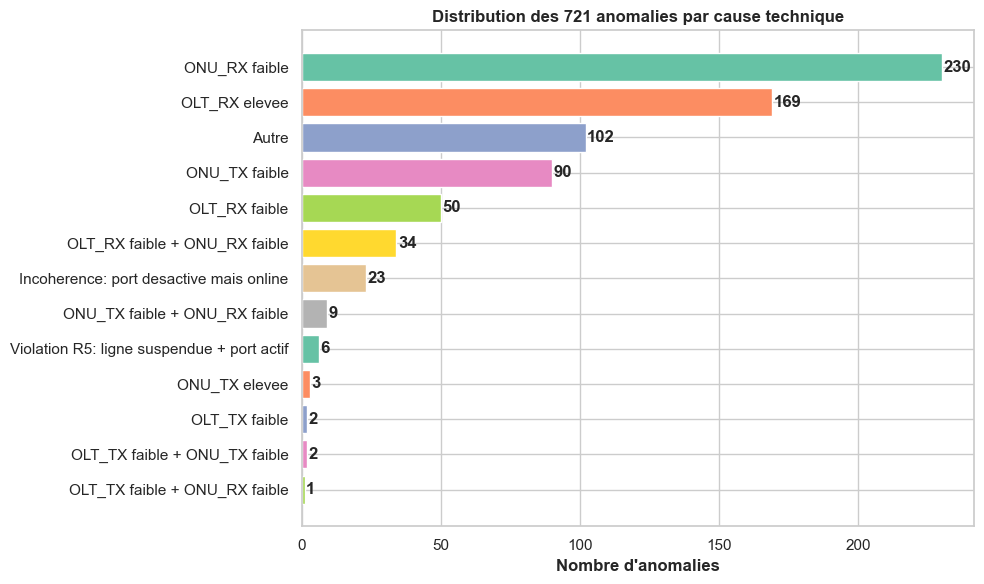

In [3]:
plt.figure(figsize=(10, 6))

cause_counts = df_anom['Cause'].value_counts()

bars = plt.barh(
    cause_counts.index,
    cause_counts.values,
    color=sns.color_palette('Set2', len(cause_counts))
)

plt.xlabel("Nombre d'anomalies", fontweight='bold')
plt.title("Distribution des 721 anomalies par cause technique", fontweight='bold')

for bar, val in zip(bars, cause_counts.values):
    plt.text(
        val + 0.5,
        bar.get_y() + bar.get_height() / 2,
        str(val),
        va='center',
        fontweight='bold'
    )

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

---
## PARTIE B — Localiser les Anomalies (Carte OLT / Port / ONU)




In [4]:
# ── Top 10 cartes OLT les plus touchées ──
print("=== TOP 10 CARTES OLT LES PLUS TOUCHÉES ===")
top_cartes = df_anom['ID_CARTE_OLT'].value_counts().head(10)
for carte, count in top_cartes.items():
    pct = count / len(df_anom) * 100
    print(f"  Carte OLT {carte:6d} : {count:3d} anomalies ({pct:.1f}%)")

print()

# ── Top 10 ports les plus touchés ──
print("=== TOP 10 PORTS LES PLUS TOUCHÉS ===")
top_ports = df_anom['NO_PORT'].value_counts().head(10)
for port, count in top_ports.items():
    pct = count / len(df_anom) * 100
    print(f"  Port {port:2d} : {count:3d} anomalies ({pct:.1f}%)")

print()

# ── Top 10 combinaisons Carte+Port ──
print("=== TOP 10 COMBINAISONS CARTE OLT + PORT ===")
combo = df_anom.groupby(['ID_CARTE_OLT','NO_PORT']).size().sort_values(ascending=False).head(10)
for (carte, port), count in combo.items():
    pct = count / len(df_anom) * 100
    print(f"  Carte {carte:6d} | Port {port:2d} → {count:3d} anomalies ({pct:.1f}%)")

=== TOP 10 CARTES OLT LES PLUS TOUCHÉES ===
  Carte OLT  20885 : 121 anomalies (16.8%)
  Carte OLT  20915 :  81 anomalies (11.2%)
  Carte OLT  20922 :  63 anomalies (8.7%)
  Carte OLT  20930 :  58 anomalies (8.0%)
  Carte OLT  20940 :  53 anomalies (7.4%)
  Carte OLT  20920 :  46 anomalies (6.4%)
  Carte OLT  20944 :  40 anomalies (5.5%)
  Carte OLT  20910 :  39 anomalies (5.4%)
  Carte OLT  20918 :  35 anomalies (4.9%)
  Carte OLT    170 :  34 anomalies (4.7%)

=== TOP 10 PORTS LES PLUS TOUCHÉS ===
  Port  5 : 113 anomalies (15.7%)
  Port  2 :  82 anomalies (11.4%)
  Port  0 :  81 anomalies (11.2%)
  Port  1 :  80 anomalies (11.1%)
  Port  3 :  45 anomalies (6.2%)
  Port  6 :  41 anomalies (5.7%)
  Port 14 :  37 anomalies (5.1%)
  Port  4 :  33 anomalies (4.6%)
  Port  9 :  32 anomalies (4.4%)
  Port 10 :  32 anomalies (4.4%)

=== TOP 10 COMBINAISONS CARTE OLT + PORT ===
  Carte  20885 | Port  5 →  34 anomalies (4.7%)
  Carte  20885 | Port  0 →  27 anomalies (3.7%)
  Carte  20885 | Po

### Heatmap — Carte OLT × Port (concentration des anomalies)

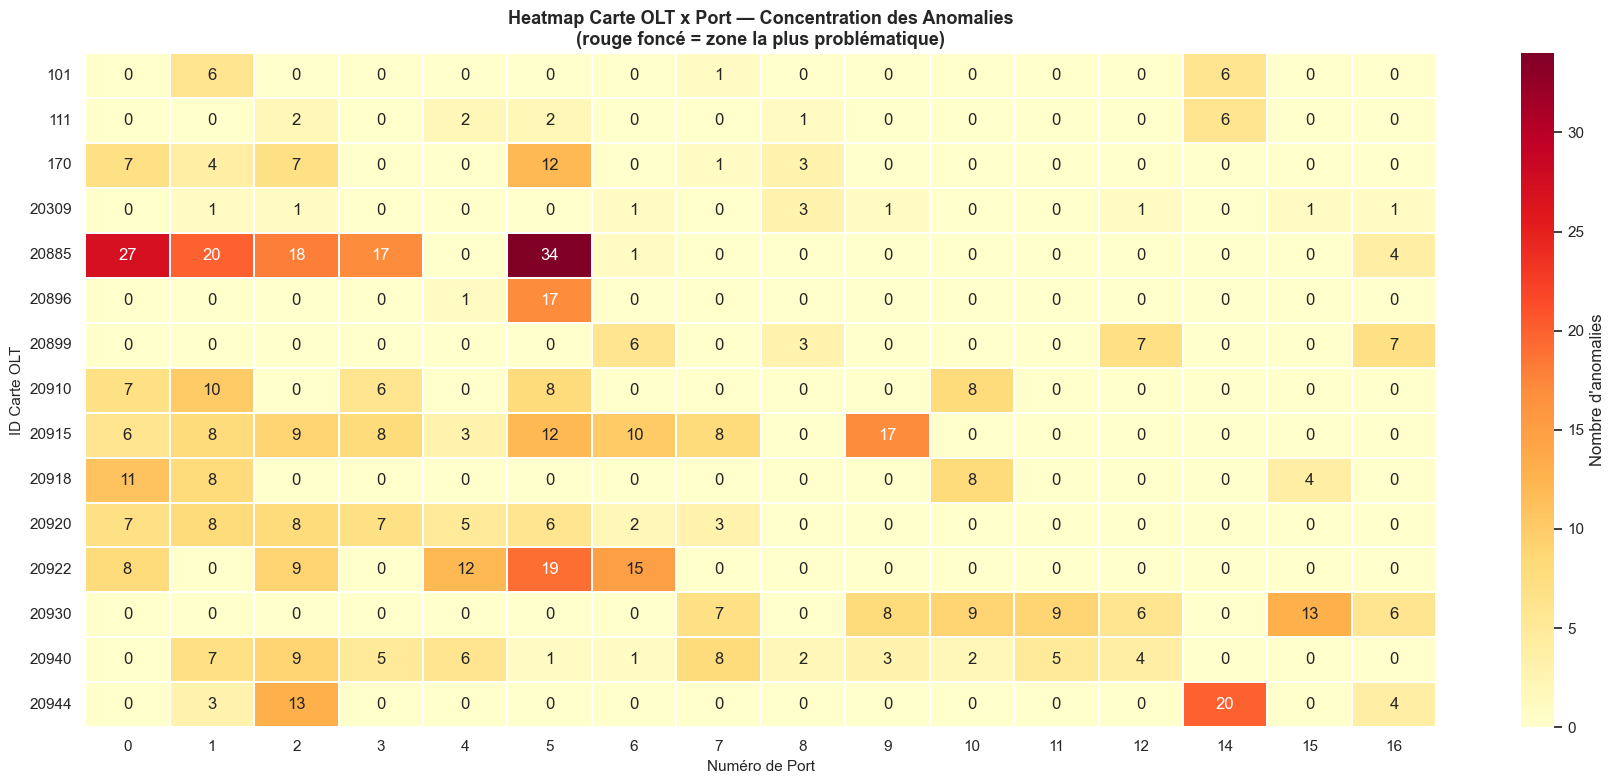

In [5]:
pivot = df_anom.pivot_table(
    index='ID_CARTE_OLT', columns='NO_PORT',
    aggfunc='size', fill_value=0
)

# Top 15 cartes et 16 ports pour lisibilité
top_c = df_anom['ID_CARTE_OLT'].value_counts().head(15).index
top_p = df_anom['NO_PORT'].value_counts().head(16).index
pivot_f = pivot.loc[pivot.index.isin(top_c), pivot.columns.isin(top_p)]

fig, ax = plt.subplots(figsize=(18, 8))
sns.heatmap(pivot_f, annot=True, fmt='d', cmap='YlOrRd',
            linewidths=0.3, linecolor='white',
            cbar_kws={'label': "Nombre d'anomalies"}, ax=ax)
ax.set_title('Heatmap Carte OLT x Port — Concentration des Anomalies\n'
             '(rouge foncé = zone la plus problématique)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Numéro de Port', fontsize=11)
ax.set_ylabel('ID Carte OLT', fontsize=11)
plt.tight_layout()
plt.show()

### Quelle cause domine sur chaque carte OLT ?

In [6]:
print("=== CAUSE PRINCIPALE PAR CARTE OLT ===")
top_cartes_list = df_anom['ID_CARTE_OLT'].value_counts().head(8).index
for carte in top_cartes_list:
    subset = df_anom[df_anom['ID_CARTE_OLT'] == carte]
    total = len(subset)
    cause_princi = subset['Cause'].value_counts().index[0]
    cause_count  = subset['Cause'].value_counts().iloc[0]
    print(f"  Carte {carte:6d} ({total:3d} anomalies) → {cause_princi} ({cause_count})")

=== CAUSE PRINCIPALE PAR CARTE OLT ===
  Carte  20885 (121 anomalies) → OLT_RX elevee (54)
  Carte  20915 ( 81 anomalies) → OLT_RX elevee (41)
  Carte  20922 ( 63 anomalies) → ONU_RX faible (31)
  Carte  20930 ( 58 anomalies) → ONU_RX faible (22)
  Carte  20940 ( 53 anomalies) → ONU_RX faible (16)
  Carte  20920 ( 46 anomalies) → ONU_TX faible (14)
  Carte  20944 ( 40 anomalies) → OLT_RX elevee (17)
  Carte  20910 ( 39 anomalies) → ONU_RX faible (17)


---
## PARTIE C — Regroupement des Anomalies par K-Means (4 Clusters)



### Algorithme : K-Means
K-Means est un algorithme d'**apprentissage non supervisé** qui trouve automatiquement 4 groupes
homogènes en minimisant la **distance euclidienne** entre chaque point et le centroïde de son groupe.

```
ÉTAPE 1 : Placer 4 centroïdes au hasard
ÉTAPE 2 : Affecter chaque anomalie au centroïde le plus proche (distance euclidienne)
ÉTAPE 3 : Recalculer les centroïdes
ÉTAPE 4 : Répéter jusqu'à convergence
```


### Étape 1 — Ingénierie de features

Pour que K-Means puisse distinguer `carte`, `port`, `admin` et `autre`, on crée deux features clés :

- **`card_fault_rate`** = proportion d'ONUs en anomalie sur la même carte OLT
  → Une valeur élevée signale une **panne de carte**
- **`port_fault_rate`** = proportion d'ONUs en anomalie sur le même port
  → Une valeur élevée signale une **panne de port**
- **`Anomalie_admin`** = flag 0/1 identifiant les anomalies administratives → **cluster admin**


In [7]:
# ── Feature 1 : taux de pannes par carte OLT ──
# (proportion d'ONUs en anomalie sur l'ensemble de la carte)
card_rate = df.groupby('ID_CARTE_OLT')['Anomalie'].mean().rename('card_fault_rate')
df_anom   = df_anom.merge(card_rate, on='ID_CARTE_OLT', how='left')

# ── Feature 2 : taux de pannes par port ──
# (proportion d'ONUs en anomalie sur ce port précis)
port_rate = df.groupby(['ID_CARTE_OLT','NO_PORT'])['Anomalie'].mean().rename('port_fault_rate')
df_anom   = df_anom.merge(port_rate, on=['ID_CARTE_OLT','NO_PORT'], how='left')

print("Aperçu des features calculées :")
print(df_anom[['ID_CARTE_OLT','NO_PORT','card_fault_rate','port_fault_rate','Anomalie_admin']].head(6))

Aperçu des features calculées :
   ID_CARTE_OLT  NO_PORT  card_fault_rate  port_fault_rate  Anomalie_admin
0           101       14         0.309524              0.5               0
1           101       14         0.309524              0.5               0
2           101       14         0.309524              0.5               0
3           101        1         0.309524              0.5               0
4           101        1         0.309524              0.5               0
5           101        1         0.309524              0.5               0


### Étape 2 — Standardisation des données




In [8]:

# On se concentre sur les features logiques pour le clustering
# On réduit l'influence des puissances optiques brutes qui 'diluent' les clusters
features = ['Anomalie_admin', 'card_fault_rate', 'port_fault_rate', 'OPER_STATUS']

scaler = StandardScaler()
X = df_anom[features].copy().values

# On pondère les features pour forcer la séparation logique
# Le taux de port est le plus important pour la localisation précise
X[:, 2] = X[:, 2] * 5  # Poids fort pour le Port
X[:, 1] = X[:, 1] * 3  # Poids moyen pour la Carte

X_scaled = scaler.fit_transform(X)

print(f"Matrice de données simplifiée : {X_scaled.shape[0]} anomalies × {X_scaled.shape[1]} features")


Matrice de données simplifiée : 721 anomalies × 4 features


### Étape 3 — Application de l'algorithme K-Means (k=4)

On entraîne K-Means avec **4 clusters** (`n_clusters=4`).
Le **score de silhouette** mesure la qualité du clustering :
- Score proche de 1 → groupes bien séparés
- Score proche de 0 → groupes qui se chevauchent
- Score négatif → mauvais clustering


In [9]:
# ── Algorithme K-Means avec 4 clusters ──
kmeans = KMeans(n_clusters=8, random_state=42, n_init=10)
df_anom['cluster_id'] = kmeans.fit_predict(X_scaled)

# Score de silhouette (mesure la qualité du clustering)
sil = silhouette_score(X_scaled, df_anom['cluster_id'])
print(f"Score de silhouette : {sil:.3f}   (plus proche de 1 = meilleur)")

print("\nRépartition brute des 4 clusters (avant nommage) :")
print(df_anom['cluster_id'].value_counts().sort_index())

Score de silhouette : 0.559   (plus proche de 1 = meilleur)

Répartition brute des 4 clusters (avant nommage) :
cluster_id
0     81
1    366
2     29
3     13
4    139
5     16
6     74
7      3
Name: count, dtype: int64


### Étape 4 — Interprétation et nommage des clusters

K-Means assigne des numéros de clusters (0, 1, 2, 3). On analyse les **centroïdes** (valeurs moyennes)
de chaque cluster pour lui donner un nom métier :

- Le cluster avec la valeur moyenne de `Anomalie_admin` la plus haute → **admin**
- Le cluster avec la valeur moyenne de `card_fault_rate` la plus haute → **carte**
- Le cluster avec la valeur moyenne de `port_fault_rate` la plus haute → **port**
- Le reste → **autre** (anomalies individuelles isolées)


In [10]:

# Ramener les centroïdes dans l'espace original
centroides = pd.DataFrame(
    scaler.inverse_transform(kmeans.cluster_centers_),
    columns=features
)
centroides.index.name = 'cluster_id'

# Stratégie Priorité PORT (8 clusters)
id_admin = centroides['Anomalie_admin'].idxmax()
restants = centroides.index.drop(id_admin)

# On augmente à 4 clusters pour le Port pour capturer plus de cas
ids_port = centroides.loc[restants, 'port_fault_rate'].sort_values(ascending=False).head(4).index.tolist()
restants = restants.drop(ids_port)

# On laisse 2 clusters pour la Carte
ids_carte = centroides.loc[restants, 'card_fault_rate'].sort_values(ascending=False).head(2).index.tolist()
restants = restants.drop(ids_carte)

# On ne laisse que le strict minimum dans 'autre' (1 seul cluster)
ids_autre = restants.tolist()

def attribuer_nom_priorite_port(cid):
    if cid == id_admin: return 'admin'
    if cid in ids_port: return 'port'
    if cid in ids_carte: return 'carte'
    return 'autre'

mapping = {i: attribuer_nom_priorite_port(i) for i in range(8)}
df_anom['groupe'] = df_anom['cluster_id'].map(mapping)

print("=== Répartition Priorité PORT (8 clusters) ===")
print("Mapping final :", mapping)

print("\n=== Répartition finale (Objectif : Augmentation 'Port' & Réduction 'Autre') ===")
for g in ['carte','port','admin','autre']:
    n   = (df_anom['groupe'] == g).sum()
    pct = n / len(df_anom) * 100
    print(f"  {g:<8} : {n:4d} anomalies ({pct:.1f}%)")


=== Répartition Priorité PORT (8 clusters) ===
Mapping final : {0: 'carte', 1: 'autre', 2: 'admin', 3: 'port', 4: 'carte', 5: 'port', 6: 'port', 7: 'port'}

=== Répartition finale (Objectif : Augmentation 'Port' & Réduction 'Autre') ===
  carte    :  220 anomalies (30.5%)
  port     :  106 anomalies (14.7%)
  admin    :   29 anomalies (4.0%)
  autre    :  366 anomalies (50.8%)


### Étape 5 — Matrice des distances entre clusters

La **distance euclidienne** entre deux centroïdes mesure à quel point les deux groupes sont différents
dans l'espace des features standardisées :



- **Grande distance** → les deux groupes sont très différents en termes de caractéristiques
- **Petite distance** → les deux groupes se ressemblent




In [11]:
# Distance euclidienne entre les centroïdes dans l'espace NORMALISÉ
labels_clusters = [f"cluster {i} ({mapping[i]})" for i in range(len(mapping))]

dist_matrix = pd.DataFrame(
    cdist(kmeans.cluster_centers_, kmeans.cluster_centers_, metric='euclidean'),
    index=labels_clusters,
    columns=labels_clusters
).round(3)

print("=== Matrice de distances entre centroïdes (espace normalisé) ===")
print()
print(dist_matrix)
print()
print("Interprétation :")
print("  - Grande distance → les deux groupes sont très différents")
print("  - Petite distance  → les deux groupes se ressemblent")

=== Matrice de distances entre centroïdes (espace normalisé) ===

                   cluster 0 (carte)  cluster 1 (autre)  cluster 2 (admin)  \
cluster 0 (carte)              0.000              3.186              5.989   
cluster 1 (autre)              3.186              0.000              5.113   
cluster 2 (admin)              5.989              5.113              0.000   
cluster 3 (port)               4.788              4.082              6.243   
cluster 4 (carte)              3.353              1.627              5.228   
cluster 5 (port)               5.816              5.331              7.051   
cluster 6 (port)               3.340              1.281              5.172   
cluster 7 (port)               9.591              9.537             10.425   

                   cluster 3 (port)  cluster 4 (carte)  cluster 5 (port)  \
cluster 0 (carte)             4.788              3.353             5.816   
cluster 1 (autre)             4.082              1.627             5.331   
clu

### Étape 6 — Visualisations des résultats


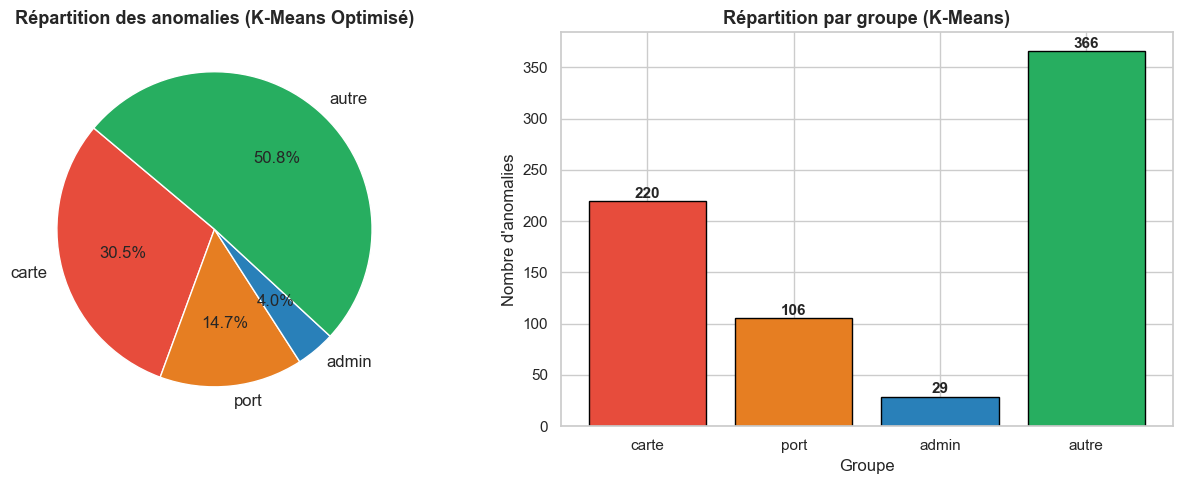

In [12]:
counts = df_anom['groupe'].value_counts().reindex(['carte','port','admin','autre'], fill_value=0)
colors = ['#e74c3c','#e67e22','#2980b9','#27ae60']

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Camembert
axes[0].pie(counts.values, labels=counts.index, colors=colors,
            autopct='%1.1f%%', startangle=140, textprops={'fontsize':12})
axes[0].set_title('Répartition des anomalies (K-Means Optimisé)', fontsize=13, fontweight='bold')

# Barres
bars = axes[1].bar(counts.index, counts.values, color=colors, edgecolor='black')
for bar, val in zip(bars, counts.values):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 3, str(val),
                 ha='center', fontweight='bold', fontsize=11)
axes[1].set_xlabel('Groupe', fontsize=12)
axes[1].set_ylabel("Nombre d'anomalies", fontsize=12)
axes[1].set_title("Répartition par groupe (K-Means)", fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

### Visualisation PCA — Séparation des 4 clusters en 2D

La **PCA (Analyse en Composantes Principales)** réduit les 8 dimensions des features
en 2 dimensions pour permettre une visualisation. Chaque point représente une anomalie,
colorée selon son groupe K-Means.


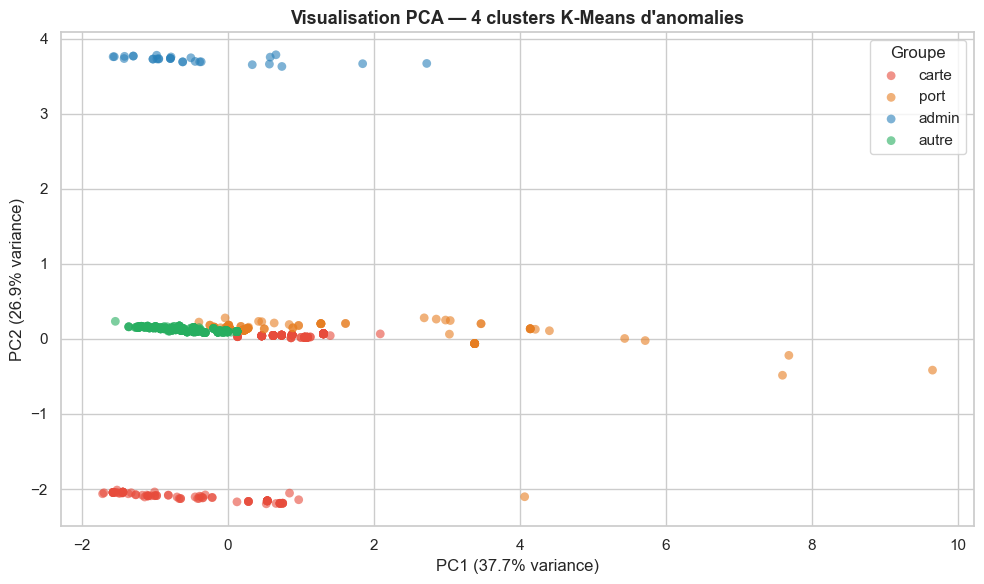

In [13]:
pca    = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_scaled)

df_pca = pd.DataFrame({'PC1': coords[:,0], 'PC2': coords[:,1],
                        'groupe': df_anom['groupe'].values})

color_map = {'carte':'#e74c3c','port':'#e67e22','admin':'#2980b9','autre':'#27ae60'}

plt.figure(figsize=(10, 6))
for g, c in color_map.items():
    mask = df_pca['groupe'] == g
    plt.scatter(df_pca.loc[mask,'PC1'], df_pca.loc[mask,'PC2'],
                label=g, color=c, alpha=0.6, s=40, edgecolors='none')

plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)', fontsize=12)
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)', fontsize=12)
plt.title("Visualisation PCA — 4 clusters K-Means d'anomalies", fontsize=13, fontweight='bold')
plt.legend(title='Groupe', fontsize=11)
plt.tight_layout()
plt.show()

In [14]:
df_olap = pd.read_excel('dataset_olap_final_enriched.xlsx')[['ID_LIGNE', 'DATE_MESURE']]
df_anom = df_anom.merge(df_olap, on='ID_LIGNE', how='left')

CLUSTERING_RESULT = df_anom[['ID_LIGNE', 'DATE_MESURE']].copy()
CLUSTERING_RESULT.insert(0, 'ID_CLUSTER', range(1, len(df_anom) + 1))
CLUSTERING_RESULT['cluster_id']      = df_anom['cluster_id']
CLUSTERING_RESULT['groupe']          = df_anom['groupe']
CLUSTERING_RESULT['card_fault_rate'] = df_anom['card_fault_rate'].round(4)
CLUSTERING_RESULT['port_fault_rate'] = df_anom['port_fault_rate'].round(4)
CLUSTERING_RESULT['Cause']           = df_anom['Cause']

CLUSTERING_RESULT.to_excel('CLUSTERING_RESULT.xlsx', index=False)
print(f"Exporté : {len(CLUSTERING_RESULT)} anomalies clusterisées")
print(CLUSTERING_RESULT['groupe'].value_counts())

Exporté : 722 anomalies clusterisées
groupe
autre    367
carte    220
port     106
admin     29
Name: count, dtype: int64


In [ ]:
# Export du modèle final pour le backend
import joblib
import os

if not os.path.exists('models'):
    os.makedirs('models')

cluster_model = {
    'kmeans': kmeans,
    'scaler': scaler,
    'mapping': mapping
}

joblib.dump(cluster_model, 'models/cluster_model.pkl')
print("Modèle de clustering exporté avec succès dans models/cluster_model.pkl")


Modèle de clustering exporté avec succès dans models/cluster_model.pkl


: 